# Test Linear Model Fixed Point Equations (with a change point)

  0%|          | 0/8 [00:00<?, ?it/s]

δ =  1.8
Optimization Results: x =  [1.16194179 1.37876056 1.63008065] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 11, 'njev': 1, 'fjac': array([[-0.90948517,  0.41066885,  0.06471333],
       [-0.39439762, -0.90151553,  0.17810182],
       [-0.13148094, -0.13645818, -0.98188183]]), 'r': array([ 0.70158145, -0.56330311, -0.1375082 ,  0.61993355, -0.31816568,
        0.23030658]), 'qtf': array([-1.85715629e-09, -3.44132242e-09, -1.58059864e-09]), 'fvec': array([ 1.05121689e-10,  3.05348635e-10, -7.71403830e-10])}
μ̃_arr:  [0.63375306 0.36624694]
σ̃ =  1.390319542703078
Regressing on signal  0


 12%|█▎        | 1/8 [00:09<01:05,  9.34s/it]

δ =  2.0
Optimization Results: x =  [1.01018782 1.26432541 1.25590972] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 10, 'njev': 1, 'fjac': array([[-0.91174056,  0.41071119,  0.00674362],
       [-0.41074832, -0.9117319 , -0.00554701],
       [-0.00387016,  0.00782737, -0.99996188]]), 'r': array([ 0.69579547, -0.53562352, -0.141999  ,  0.65361199, -0.30444917,
        0.34590047]), 'qtf': array([ 1.14026781e-11, -1.58540643e-11,  5.09406097e-11]), 'fvec': array([-8.17124146e-14,  4.77395901e-14, -2.66453526e-13])}
μ̃_arr:  [0.64764093 0.35235907]
σ̃ =  1.2469416611322242
Regressing on signal  0


 25%|██▌       | 2/8 [00:20<01:02, 10.34s/it]

δ =  2.5
Optimization Results: x =  [0.8984277  1.22488164 0.7892764 ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 8, 'njev': 1, 'fjac': array([[-0.92004412,  0.39179129, -0.00428968],
       [-0.39181136, -0.92002668,  0.00589622],
       [ 0.00163653, -0.00710553, -0.99997342]]), 'r': array([ 0.68437589, -0.48863186, -0.20314992,  0.7487595 , -0.48239541,
        0.67728391]), 'qtf': array([ 1.77620732e-12, -2.38017916e-12, -1.93195451e-12]), 'fvec': array([ 7.77156117e-15, -1.13242749e-14, -7.77156117e-15])}
μ̃_arr:  [0.6713212 0.3286788]
σ̃ =  1.2130839417609276
Regressing on signal  0


... (7 outputs left out)

δ =  4.5
Optimization Results: x =  [0.62227995 1.10581386 0.31059328] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 15, 'njev': 1, 'fjac': array([[-0.95389538,  0.29413846, -0.05971746],
       [-0.29742073, -0.95307506,  0.05646984],
       [ 0.04030527, -0.07162753, -0.99661677]]), 'r': array([ 0.72054324, -0.26959606, -0.56622196,  1.06901847, -1.6888057 ,
        2.21510571]), 'qtf': array([ 2.91948918e-12,  3.40882033e-12, -2.42350030e-13]), 'fvec': array([-9.60342916e-14, -5.81756865e-14,  4.66293670e-15])}
μ̃_arr:  [0.70935153 0.29064847]
σ̃ =  0.9919192518506973
Regressing on signal  0


 88%|████████▊ | 7/8 [01:17<00:11, 11.40s/it]

δ =  5.0
Optimization Results: x =  [0.59608799 1.09941264 0.26924497] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 14, 'njev': 1, 'fjac': array([[-0.97234851,  0.22390338, -0.06637513],
       [-0.2286039 , -0.97066066,  0.07455292],
       [ 0.04773508, -0.08766503, -0.99500563]]), 'r': array([ 0.78613438, -0.30273387,  0.82391998,  1.01745312, -0.60627432,
        2.58743019]), 'qtf': array([-2.27372521e-09, -1.92330588e-09, -8.60818651e-11]), 'fvec': array([-2.4745983e-11, -1.3774093e-11,  4.8361315e-13])}
μ̃_arr:  [0.71375073 0.28624927]
σ̃ =  0.9791661693153448
Regressing on signal  0


100%|██████████| 8/8 [01:29<00:00, 11.22s/it]


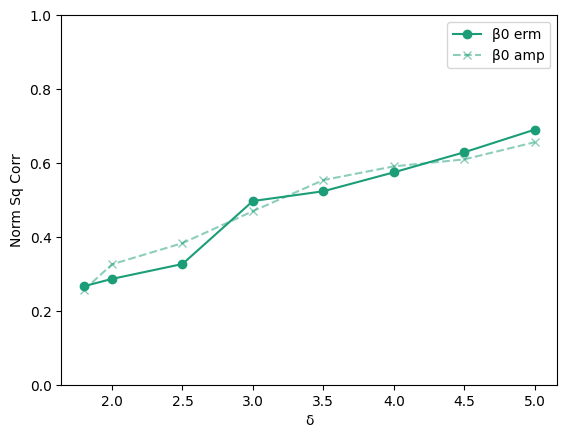

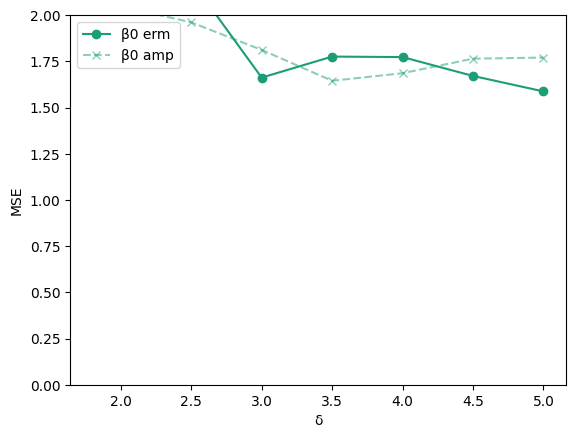

In [1]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 2 # num signals. L-1 changepoints

δ_list = [1.8, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
noise_std = 0.5
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    # --- Run Weighted ERM and compare with the fixed point equations --- #
    B̂ = np.zeros((p, L))

    ℓ_ = 0
    # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
    μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
    print("σ̃ = ", σ̃)
    β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

    print("Regressing on signal ", ℓ_)
    sample_weight = (n - np.arange(n)) / n
    sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
    sk_lin_reg.fit(X, y, sample_weight = sample_weight)
    β̂ = sk_lin_reg.coef_

    B̂[:, ℓ_] = β̂
    erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
    amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

    comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
    comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
    erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
    amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
    G = np.random.randn(p)
    theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
ℓ_ = 0
plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
# plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()